# 03 · EDA del problema: inseguridad y actividad económica en la CDMX

Este notebook no repite el EDA de factibilidad (`docs/_factibilidad/02-eda.md`, que respondió *"¿alcanzan los datos?"*), sino que responde *"¿qué nos dicen los datos sobre el problema?"*. Deja la evidencia para las decisiones de especificación: la variable objetivo (S1), el corte del DENUE (S2), la validación temporal (S3), la inclusión de 2019 (S4) y la lista de giros intensivos en efectivo.

- Datos: `data/processed/panel_ageb_anio.parquet` (generado por `01_datos.py` y `02_features.py`; diccionario en `analisis/pipeline/README.md`).
- Figuras: `analisis/pipeline/outputs/eda/figNN_*.png`.
- Detalle de cada decisión, con opciones e implicaciones: `analisis/pipeline/outputs/eda/decisiones.md`.

## 0. Registro de hipótesis (antes de modelar)

Las hipótesis y sus criterios de rechazo se fijaron en el diseño experimental (`docs/5.Diseno-Experimental.md` §2) antes de ajustar cualquier modelo, y aquí se citan textualmente. Lo único que se ajustó antes es el β de un Poisson simple sin controles en el EDA de factibilidad, solo como orden de magnitud.

| | Hipótesis | Prueba | Criterio de rechazo (declarado ex ante) | Si se confirma → recomendación |
|---|---|---|---|---|
| **A. ¿Cuánto?** | El robo a negocio crece *menos que proporcionalmente* con el número de establecimientos (β < 1) | β de log(establecimientos) en M0/M1; IC 95% por *bootstrap* de bloques espaciales | Límite superior del IC 95% ≥ 1 | La densidad comercial protege: priorizar apoyo a negocios aislados o de baja densidad |
| **B. ¿Cuáles?** | La composición del tejido económico (giros intensivos en efectivo) explica el robo mejor que el conteo total | Mejora relativa de la devianza Poisson fuera de muestra, M0 → M1, en validación espacial | ΔD < 5% **o** mejora en menos de 4 de 5 *folds* | Focalizar apoyos por giro, no solo por zona |
| **C. ¿Dónde?** | Priorizar por riesgo residual identifica zonas distintas a priorizar por conteo crudo, y esas zonas persisten en el tiempo | Jaccard entre el top 10% por conteo y el top 10% por P(θ > 1); Spearman del riesgo contraído entre años consecutivos | Jaccard > 0.5 (no cambia la priorización) **o** ρ medio < 0.3 (el residual es ruido) | Lista de "zonas que el conteo no ve" como recomendación principal a SEDECO |

Las vistas previas de este notebook son **descriptivas** (sin validación fuera de muestra). No confirman ni rechazan nada: las pruebas formales se hacen al modelar (`04_modelos.py`) con estos mismos criterios.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from common import CANDIDATOS_EFECTIVO, INTERIM, LISTA_TENTATIVA, OUT_EDA, RAW, ROOT, lee_panel

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
COL = {"V1": "#c0392b", "V2": "#e67e22", "V2b": "#f1c40f", "V3": "#2c7fb8", "farderos": "#7f8c8d", "E": "#2ca25f"}

p = lee_panel()
VARS = {"V1": "y_v1_negocio", "V2": "y_v2_sin_farderos", "V2b": "y_v2b", "V3": "y_v3_via_publica"}
NOMBRE = {"V1": "V1 robo a negocio", "V2": "V2 negocio sin farderos", "V2b": "V2b sin farderos ni S/V dentro",
          "V3": "V3 robo en vía pública"}


def guarda(fig, nombre):
    fig.savefig(OUT_EDA / f"{nombre}.png", bbox_inches="tight")


def poisson(X, y, offset=None):
    # GLM Poisson por IRLS. Devuelve coeficientes y EE quasi-Poisson (escalados por la dispersión de Pearson).
    # Solo para vistas previas descriptivas: no es M0/M1 (que son NB con validación espacial, en 04_modelos.py).
    X = np.column_stack([np.ones(len(y)), X]).astype(float)
    off = np.zeros(len(y)) if offset is None else offset
    b = np.zeros(X.shape[1]); b[0] = np.log(y.mean())
    for _ in range(100):
        eta = X @ b + off; mu = np.exp(eta)
        z = eta - off + (y - mu) / mu
        bn = np.linalg.solve(X.T @ (mu[:, None] * X), X.T @ (mu * z))
        if np.abs(bn - b).max() < 1e-9:
            b = bn; break
        b = bn
    mu = np.exp(X @ b + off)
    phi = ((y - mu) ** 2 / mu).sum() / (len(y) - X.shape[1])
    se = np.sqrt(np.diag(np.linalg.inv(X.T @ (mu[:, None] * X))) * phi)
    return b, se, phi


def periodo(anios=range(2020, 2025), e="E_fijo"):
    # Suma del periodo por AGEB (E fijo). Muestra de modelado: E > 0.
    s = p[p.anio.isin(anios) & (p[e] > 0)]
    agg = {k: (v, "sum") for k, v in VARS.items()}
    agg |= {"farderos": ("y_farderos", "sum"), "dentro": ("y_negocio_sv_dentro", "sum"), "E": (e, "first"),
            "ag": ("n_autoserv_grande_fijo", "first"),
            "alcaldia": ("alcaldia", "first"), "colonia": ("colonia", "first")}
    agg |= {c: (f"pc_{c}_fijo", "first") for c in CANDIDATOS_EFECTIVO}
    out = s.groupby("cvegeo").agg(**agg)
    out["pe"] = out[LISTA_TENTATIVA].sum(axis=1)  # proporción de la lista tentativa del diseño
    return out


def top(x, q=0.10):
    return set(x.sort_values(ascending=False).index[: int(round(len(x) * q))])


def jaccard(a, b):
    return len(a & b) / len(a | b)


per = periodo()
print(p.shape, "| AGEB en la muestra de modelado (E_fijo > 0):", len(per))

(14586, 73) | AGEB en la muestra de modelado (E_fijo > 0): 2419


## 1. Datos y limpieza: qué se perdió en cada paso y por qué es aceptable

El pipeline (`01_datos.py`, `02_features.py`) aplica estas transformaciones. Cada una tiene su supuesto comentado junto al código; aquí se resume con su costo medido.

In [2]:
d = pd.read_parquet(INTERIM / "delitos_ageb.parquet")
perd = (pd.crosstab(d.objetivo, d.tipo_asig, margins=True, margins_name="total")
        .reindex(columns=["URBANA", "RURAL", "SIN_COORD", "total"]))
perd_pct = perd.div(perd["total"], axis=0).mul(100).round(2).drop(columns="total")
print("Destino de las carpetas de interés 2019–2024 (% por fila):")
display(perd_pct)
e0 = p[(p.anio == 2023) & (p.E_fijo == 0)]
print(f"AGEB con E_fijo = 0 (se excluyen al modelar): {len(e0)} | robos a negocio 2019–2024 en ellas: "
      f"{int(p[p.E_fijo == 0].y_v1_negocio.sum())} de {int(p.y_v1_negocio.sum())}")

Destino de las carpetas de interés 2019–2024 (% por fila):


tipo_asig,URBANA,RURAL,SIN_COORD
objetivo,,,
ampliado,99.41,0.25,0.34
negocio,99.65,0.02,0.33
via_publica,97.94,0.07,1.99
total,98.87,0.05,1.07


AGEB con E_fijo = 0 (se excluyen al modelar): 12 | robos a negocio 2019–2024 en ellas: 5 de 87226


| Paso | Supuesto (por qué es válido aquí) | Costo medido |
|---|---|---|
| Fuente: parquet de la API FGJ por **año del hecho** | El 98% de los hechos se denuncia el mismo año; la API llega a `fecha_inicio` 2025-01, así que 2024 está completo al ~99%. El CSV 2024 está truncado en julio y no se usa | — |
| Homologación de 45 valores de `delito` en 3 variables objetivo (`analisis/pipeline/config/homologacion_fgj.csv`, con justificación por fila) | Los agregados son comparables entre años aunque los subtipos no lo sean (reforma de 2020). El pipeline falla si aparece un valor no homologado | Excluidos: oficina pública, taxi, extorsión (fuera de alcance) |
| Coordenada válida = no nula, ≠ 0 y dentro del polígono CDMX | Sin coordenada no hay forma de ubicar el hecho; la pérdida es casi toda por nulos, no por errores | 0.33% negocio, 1.99% vía pública |
| Solo AGEB urbanas (MG2020, 2,431) | El problema es urbano; las AGEB rurales casi no tienen negocios | <0.1% de los delitos |
| Exposición `E` = establecimientos DENUE en la AGEB (unión espacial por coordenada) | Coincide con la clave AGEB del propio DENUE en el 99.8–99.99% | 0.25–0.36% de los establecimientos caen en AGEB rurales |
| Excluir AGEB con E = 0 | Sin exposición no hay "esperado"; casi no tienen delitos | 12 AGEB, 4 robos a negocio en 6 años |
| Población 2020 (`log(POBTOT+1)`) + indicador `no_residencial` (POBTOT = 0) | El censo es transversal; la población por AGEB cambia poco en 4 años | 17 AGEB no residenciales, todas con establecimientos |
| Distancia a la estación de Metro/Metrobús abierta ese año | Proxy de flujo peatonal; se usa el año de apertura del SHP oficial. La L12 cuenta como cerrada en 2021–2022 | Mediana ≈ 1 km |
| Colonia dominante por área (catálogo CDMX) | Solo es etiqueta para la app; los modelos no la usan | 13 AGEB fuera del catálogo toman la colonia más cercana |

In [3]:
h = pd.read_csv(ROOT / "analisis/pipeline/outputs/homologacion_fgj_final.csv")
ncols = [f"n_{a}" for a in range(2019, 2025)]
res = h[h.objetivo != "excluir"].groupby(["objetivo", "grupo"])[ncols].sum().astype(int)
print("Homologación: carpetas por grupo y año del hecho (antes de filtrar coordenadas)")
display(res)

Homologación: carpetas por grupo y año del hecho (antes de filtrar coordenadas)


n_2019  n_2020  n_2021  n_2022  n_2023  n_2024
objetivo    grupo                                                                 
ampliado    transeunte_en_lugar        896    1164    2282    1914    1642    1831
negocio     negocio_cv                5068    1901    2583    2155    1923    1719
            negocio_cv_farderos          6    1582     139      36      46      76
            negocio_cv_otros            48      15      12      12      10       5
            negocio_sv               15776    4482    3559    2486    2508    2431
            negocio_sv_dentro           15     974     951    1197    1336    1234
            negocio_sv_farderos         56    7584    6350    6389    7298    5570
via_publica cuentahabiente             652     367     309     298     206     143
            repartidor                3483    2380    2041    1403     900     742
            transeunte_via_publica   16515   10357   10980   10507    8824    8039

### 1.1 Las variables objetivo candidatas

Además de V1, V2 y V3 (diseño §3), el EDA agrega **V2b = V2 sin "S/V dentro de negocios"**, una categoría que la FGJ crea en 2020, igual que los farderos. Abajo se ve por qué.

In [4]:
def resumen(s):
    return pd.Series({"total": s.sum(), "media": s.mean(), "% ceros": (s == 0).mean() * 100, "var/media": s.var() / s.mean()})

m = p[p.E_fijo > 0]
tab = pd.DataFrame({k: resumen(m.loc[m.anio >= (2020 if k in ("V2", "V2b") else 2019), v]) for k, v in VARS.items()}).T
tab.index = [NOMBRE[k] + (" (2020–24)" if k in ("V2", "V2b") else " (2019–24)") for k in tab.index]
display(tab.round(1))
print("% de ceros por año:")
display(m.groupby("anio")[list(VARS.values())].apply(lambda g: (g == 0).mean() * 100).round(1).set_axis(list(VARS), axis=1))

,total,media,% ceros,var/media
V1 robo a negocio (2019–24),87221.0,6.0,30.0,58.4
V2 negocio sin farderos (2020–24),31286.0,2.6,36.3,10.0
V2b sin farderos ni S/V dentro (2020–24),25615.0,2.1,38.4,7.1
V3 robo en vía pública (2019–24),76522.0,5.3,14.5,9.2


% de ceros por año:


,V1,V2,V2b,V3
anio,,,,
2019,23.2,23.2,23.2,9.6
2020,26.9,34.3,35.5,13.1
2021,29.4,32.9,34.7,12.3
2022,32.9,37.1,39.3,13.8
2023,33.2,36.9,39.4,18.2
2024,34.1,40.0,43.0,19.8


Todas las variantes cumplen el criterio de < 70% de ceros y tienen sobredispersión fuerte (var/media ≫ 1), lo que justifica la binomial negativa sobre Poisson (la prueba formal se hace al modelar). V2b es la más escasa (43% de ceros en 2024), pero sigue lejos del umbral.

## 2. Vista previa de A: ¿el robo crece menos que proporcionalmente con los establecimientos?

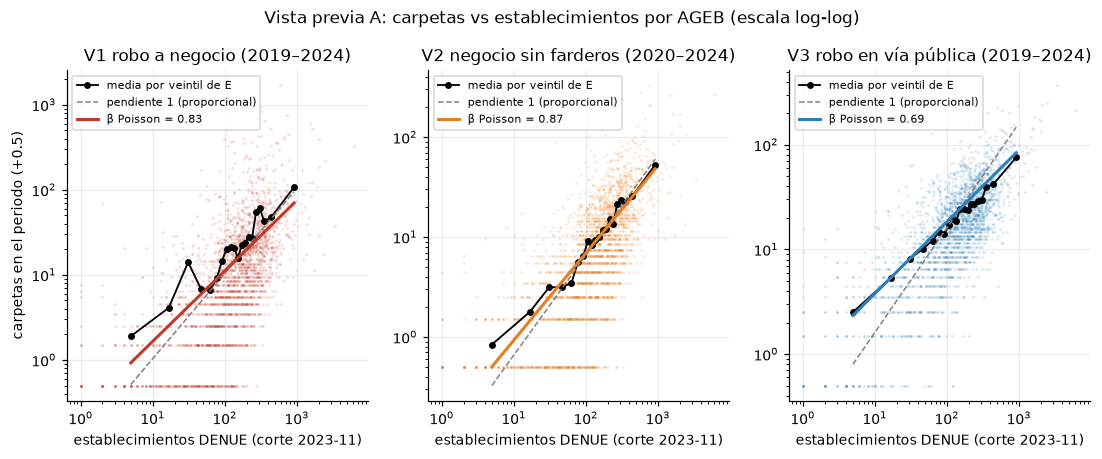

,pendiente total,mitad baja de E,mitad alta de E
variable,,,
V1,0.79,0.73,0.96
V2,0.85,0.78,0.90
V2b,0.85,0.79,0.82
V3,0.64,0.63,0.65
farderos,0.75,0.70,1.04


{'V1': 'β = 0.828 (EE quasi-Poisson 0.026)', 'V2': 'β = 0.874 (EE quasi-Poisson 0.014)', 'V3': 'β = 0.686 (EE quasi-Poisson 0.008)'}


In [5]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.9), sharex=True)
betas = {}
for ax, k in zip(axs, ["V1", "V2", "V3"]):
    anios = range(2019, 2025) if k != "V2" else range(2020, 2025)
    s = p[p.anio.isin(anios) & (p.E_fijo > 0)]
    fe = pd.get_dummies(s.anio, drop_first=True).values
    b, se, _ = poisson(np.column_stack([np.log(s.E_fijo), fe]), s[VARS[k]].values.astype(float))
    betas[k] = (b[1], se[1])
    g = per[[k, "E"]]
    ax.scatter(g.E, g[k] + 0.5, s=3, alpha=0.18, color=COL[k], lw=0)
    # medias por 20 cuantiles de E (sin problema de ceros)
    q = pd.qcut(g.E, 20, labels=False)
    bm = g.groupby(q).mean()
    ax.plot(bm.E, bm[k], "o-", color="k", ms=3.5, lw=1.2, label="media por veintil de E")
    x = np.geomspace(bm.E.min(), bm.E.max(), 50)
    ref = bm[k].iloc[10] * (x / bm.E.iloc[10])
    ax.plot(x, ref, "--", color="gray", lw=1, label="pendiente 1 (proporcional)")
    ax.plot(x, bm[k].iloc[10] * (x / bm.E.iloc[10]) ** b[1], color=COL[k], lw=2, label=f"β Poisson = {b[1]:.2f}")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(f"{NOMBRE[k]} ({min(anios)}–2024)")
    ax.set_xlabel("establecimientos DENUE (corte 2023-11)")
    ax.legend(fontsize=7, loc="upper left")
axs[0].set_ylabel("carpetas en el periodo (+0.5)")
fig.suptitle("Vista previa A: carpetas vs establecimientos por AGEB (escala log-log)", y=1.02)
guarda(fig, "fig01_A_loglog_variantes")
plt.show()

# ¿los farderos curvan la relación? pendiente de las medias por decil en la mitad baja vs alta de E
filas = []
for k in ["V1", "V2", "V2b", "V3", "farderos"]:
    g = per[[k, "E"]]
    bm = g.groupby(pd.qcut(g.E, 10, labels=False)).mean()
    sl = lambda a: np.polyfit(np.log(a.E), np.log(a[k]), 1)[0]
    filas.append({"variable": k, "pendiente total": sl(bm), "mitad baja de E": sl(bm.iloc[:5]), "mitad alta de E": sl(bm.iloc[5:])})
display(pd.DataFrame(filas).set_index("variable").round(2))
print({k: f"β = {b:.3f} (EE quasi-Poisson {s:.3f})" for k, (b, s) in betas.items()})

**Lectura.**
- Las tres variantes crecen **menos que proporcionalmente**: β ≈ 0.83 (V1, 2019–2024; 0.81 en 2020–2024), 0.87 (V2) y 0.69 (V3), con efectos fijos de año y sin controles. La señal es compatible con la hipótesis A, pero el IC formal (bootstrap espacial) y los controles quedan para el modelado.
- **Los farderos curvan la relación.** En la mitad alta de E, la pendiente de V1 sube de 0.73 a 0.96 y la de los farderos supera 1 (1.04). En las AGEB más comerciales (centros comerciales, autoservicios) el robo hormiga se acumula *más* que proporcionalmente, y eso tira de β hacia 1. V2 todavía se curva (0.78 → 0.90); solo V2b, que además quita "S/V dentro de negocios" (§3), queda casi recta (0.79 → 0.82).
- El robo en vía pública (V3) es el más sublineal y el más recto: su relación con la densidad comercial es más estable y menos dominada por unos pocos establecimientos.

## 3. Evidencia para S1: ¿los farderos entran en la variable objetivo?

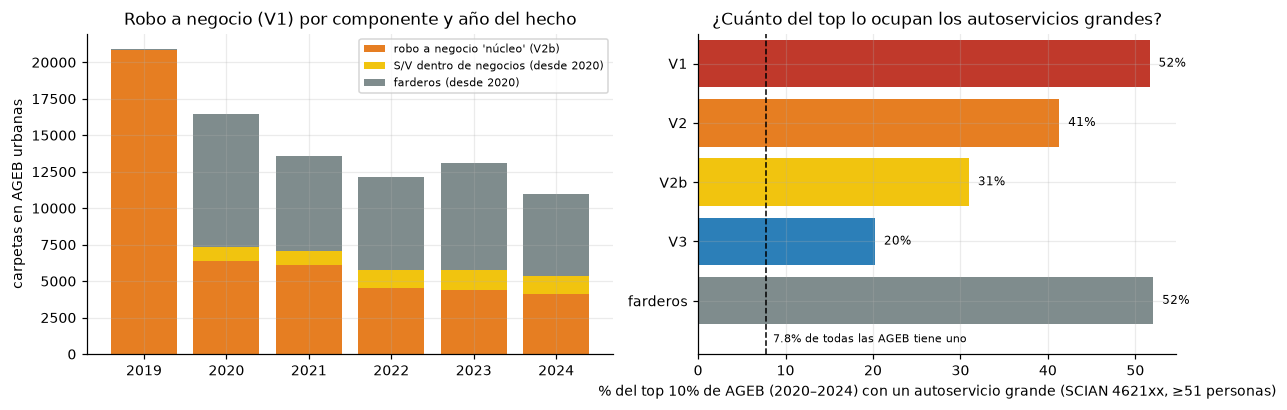

,% en AGEB con autoservicio grande,% en el top 10% de AGEB,Jaccard top 10% vs V1
variable,,,
V1,46.15,62.08,1.00
V2,27.09,45.50,0.61
V2b,21.75,41.05,0.50
V3,13.01,33.92,0.23
farderos,63.17,80.37,0.73
dentro,51.21,79.47,0.51


Las AGEB con autoservicio grande son 188 (7.8%) y tienen el 12.6% de los establecimientos.
Spearman (rangos por AGEB) farderos vs S/V dentro: 0.59


In [6]:
comp = p.groupby("anio")[["y_v2b", "y_negocio_sv_dentro", "y_farderos"]].sum()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axs[0]
bot = np.zeros(len(comp))
for c, lab, col in [("y_v2b", "robo a negocio 'núcleo' (V2b)", COL["V2"]),
                    ("y_negocio_sv_dentro", "S/V dentro de negocios (desde 2020)", COL["V2b"]),
                    ("y_farderos", "farderos (desde 2020)", COL["farderos"])]:
    ax.bar(comp.index, comp[c], bottom=bot, color=col, label=lab)
    bot += comp[c].values
ax.set_title("Robo a negocio (V1) por componente y año del hecho")
ax.set_ylabel("carpetas en AGEB urbanas"); ax.legend(fontsize=7)

ax = axs[1]
base = (per.ag > 0).mean() * 100
vals = {k: np.mean([per.ag[i] > 0 for i in top(per[k])]) * 100 for k in ["V1", "V2", "V2b", "V3"]}
vals["farderos"] = np.mean([per.ag[i] > 0 for i in top(per.farderos)]) * 100
ax.barh(list(vals)[::-1], list(vals.values())[::-1], color=[COL[k] for k in list(vals)[::-1]])
ax.axvline(base, color="k", ls="--", lw=1)
ax.set_ylim(-0.9, 4.5)
ax.text(base + 0.8, -0.7, f"{base:.1f}% de todas las AGEB tiene uno", fontsize=7)
for i, v in enumerate(list(vals.values())[::-1]):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8)
ax.set_xlabel("% del top 10% de AGEB (2020–2024) con un autoservicio grande (SCIAN 4621xx, ≥51 personas)")
ax.set_title("¿Cuánto del top lo ocupan los autoservicios grandes?")
fig.tight_layout()
guarda(fig, "fig02_S1_farderos")
plt.show()

conc = lambda s: s.sort_values(ascending=False).iloc[: int(len(s) * 0.1)].sum() / s.sum() * 100
filas = []
for k in ["V1", "V2", "V2b", "V3", "farderos", "dentro"]:
    filas.append({"variable": k, "% en AGEB con autoservicio grande": per.loc[per.ag > 0, k].sum() / per[k].sum() * 100,
                  "% en el top 10% de AGEB": conc(per[k]),
                  "Jaccard top 10% vs V1": jaccard(top(per[k]), top(per.V1))})
s1 = pd.DataFrame(filas).set_index("variable").round(2)
display(s1)
print(f"Las AGEB con autoservicio grande son {(per.ag > 0).sum()} ({base:.1f}%) y tienen el "
      f"{per.loc[per.ag > 0, 'E'].sum() / per.E.sum() * 100:.1f}% de los establecimientos.")
print("Spearman (rangos por AGEB) farderos vs S/V dentro:", round(stats.spearmanr(per.farderos, per.dentro)[0], 2))

In [7]:
# ¿qué AGEB dominan V1 y no V2? las 10 con más farderos en el periodo
t = per.assign(pct_farderos=per.farderos / per.V1 * 100).sort_values("farderos", ascending=False).head(10)
display(t[["alcaldia", "colonia", "E", "ag", "V1", "V2", "farderos", "dentro", "pct_farderos"]]
        .rename(columns={"ag": "autoserv. grandes"}).round(0))

,alcaldia,colonia,E,autoserv. grandes,V1,V2,farderos,dentro,pct_farderos
cvegeo,,,,,,,,,
090150001049A,Cuauhtémoc,Buenavista,578,3,1688,282,1406,95,83.0
0900500011805,Gustavo A. Madero,Bondojito,274,3,1579,244,1335,111,85.0
0900500013407,Gustavo A. Madero,D M Nacional,38,1,1199,89,1110,39,93.0
0901400010825,Benito Juárez,Santa Cruz Atoyac,271,4,1241,236,1005,101,81.0
0900300011105,Coyoacán,Jardines Del Pedregal De San Angel,320,1,948,240,708,77,75.0
0901400010026,Benito Juárez,Piedad Narvarte,321,1,842,233,609,90,72.0
0901700010795,Venustiano Carranza,Industrial Puerto Aereo,289,1,672,91,581,45,86.0
0901600010302,Miguel Hidalgo,Periodista,353,2,646,76,570,32,88.0
090020001074A,Azcapotzalco,Victoria De Las Democracias,119,1,605,73,532,44,88.0


**Lectura.**
- Desde 2020, los farderos son ~50% del robo a negocio, y 63% de ellos cae en el 7.8% de las AGEB que tienen un autoservicio grande (con 12.6% de los establecimientos). El top 10% de V1 está ocupado en 52% por esas AGEB. Lo que domina el ranking de V1 es *dónde hay un autoservicio grande* que denuncia sistemáticamente, no necesariamente *dónde es inseguro operar un negocio*. En las 10 AGEB con más farderos, estos son entre 72% y 93% de su V1. El caso extremo (`0900500013407`, GAM) tiene 1,110 farderos con solo 38 establecimientos en el DENUE: una sola tienda grande.
- **Hallazgo: "S/V dentro de negocios" se comporta como farderos.** Nace en 2020 junto con ellos, 51% cae en AGEB con autoservicio grande, su concentración es igual (top 10% ≈ 80%) y su ranking por AGEB correlaciona con el de farderos (ρ ≈ 0.59). Lo más probable es que sea robo hormiga sin la etiqueta. Por eso V2 todavía tiene 41% del top en AGEB con autoservicio grande, y solo **V2b** baja a 31%, más cerca de V3 (20%).
- El costo de V2/V2b: no son comparables con 2019 (antes de 2020 no se pueden separar), así que el periodo queda en 2020–2024, y tienen más ceros.
- El Jaccard del top 10% frente a V1 es de 0.61 (V2) y 0.50 (V2b): excluir farderos sí cambia a quién se prioriza, aunque no por completo.

## 4. Vista previa de B: composición del tejido económico y lista de giros intensivos en efectivo

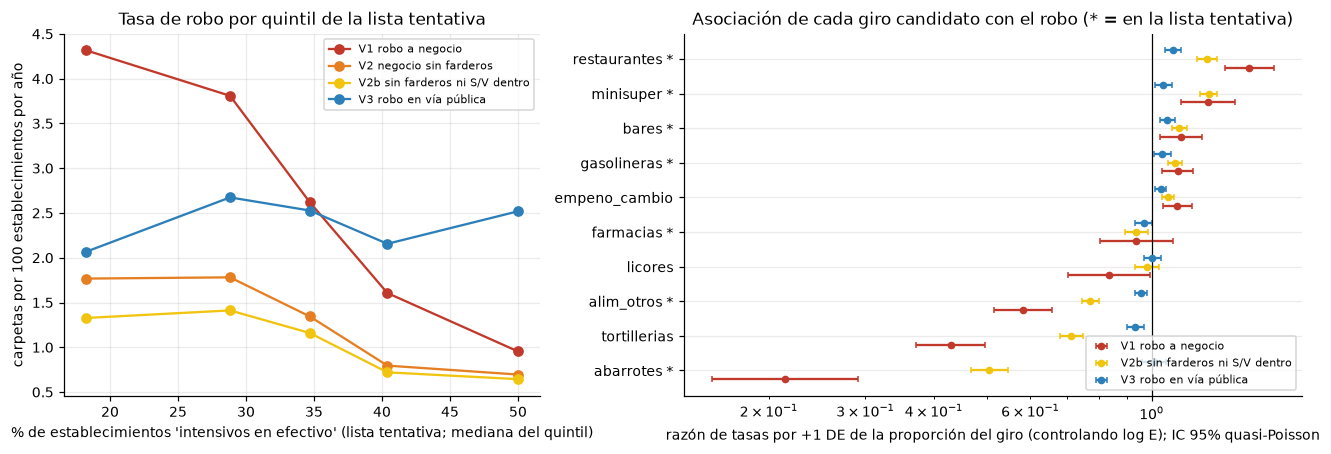

,V1,V2b,V3,mediana_%,p90_%,n_estab
giro,,,,,,
restaurantes,1.50,1.26,1.09,11.45,19.51,57574
minisuper,1.27,1.27,1.05,0.33,1.70,3007
bares,1.13,1.12,1.07,0.00,0.64,1054
gasolineras,1.12,1.10,1.05,0.00,0.52,712
empeno_cambio,1.11,1.07,1.04,0.00,0.26,586
farmacias,0.94,0.94,0.97,1.83,3.72,9064
licores,0.84,0.98,1.00,0.00,0.93,1441
alim_otros,0.58,0.77,0.95,6.77,16.46,46184
tortillerias,0.43,0.71,0.93,1.27,3.17,6250


In [8]:
k5 = pd.qcut(per.pe, 5, labels=False)
g = per.groupby(k5).agg(E=("E", "sum"), pe=("pe", "median"), **{k: (k, "sum") for k in VARS})
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axs[0]
for k in ["V1", "V2", "V2b", "V3"]:
    ax.plot(g.pe * 100, g[k] / g.E / 5 * 100, "o-", color=COL[k], label=NOMBRE[k])
ax.set_xlabel("% de establecimientos 'intensivos en efectivo' (lista tentativa; mediana del quintil)")
ax.set_ylabel("carpetas por 100 establecimientos por año")
ax.set_title("Tasa de robo por quintil de la lista tentativa")
ax.legend(fontsize=7)

# RR por +1 DE de la proporción de cada giro candidato, controlando log E (quasi-Poisson, periodo 2020–2024)
filas = []
for c in CANDIDATOS_EFECTIVO:
    x = per[c] / per[c].std()
    for k in ["V1", "V2b", "V3"]:
        b, se, _ = poisson(np.column_stack([np.log(per.E), x]), per[k].values.astype(float))
        filas.append({"giro": c, "var": k, "rr": np.exp(b[2]), "lo": np.exp(b[2] - 1.96 * se[2]), "hi": np.exp(b[2] + 1.96 * se[2]),
                      "mediana_%": per[c].median() * 100, "p90_%": per[c].quantile(0.9) * 100,
                      "n_estab": int((per[c] * per.E).sum())})
rr = pd.DataFrame(filas)
orden = rr[rr["var"] == "V1"].sort_values("rr").giro.tolist()
ax = axs[1]
for j, k in enumerate(["V1", "V2b", "V3"]):
    r = rr[rr["var"] == k].set_index("giro").loc[orden]
    yy = np.arange(len(orden)) + (j - 1) * 0.25
    ax.errorbar(r.rr, yy, xerr=[r.rr - r.lo, r.hi - r.rr], fmt="o", ms=4, color=COL[k], label=NOMBRE[k], capsize=2)
ax.axvline(1, color="k", lw=0.8)
ax.set_xscale("log")
ax.set_yticks(range(len(orden)))
ax.set_yticklabels([f"{c}{' *' if c in LISTA_TENTATIVA else ''}" for c in orden])
ax.set_xlabel("razón de tasas por +1 DE de la proporción del giro (controlando log E); IC 95% quasi-Poisson")
ax.set_title("Asociación de cada giro candidato con el robo (* = en la lista tentativa)")
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
guarda(fig, "fig03_B_composicion_giros")
plt.show()
display(rr.pivot(index="giro", columns="var", values="rr").join(rr.drop_duplicates("giro").set_index("giro")[["mediana_%", "p90_%", "n_estab"]]).loc[orden[::-1]].round(2))

In [9]:
# ¿Quién tiene alta proporción de tienditas? perfil de las AGEB por quintil de abarrotes+alimentos+tortillerías
tienditas = per.abarrotes + per.alim_otros + per.tortillerias
q = pd.qcut(tienditas, 5, labels=["Q1 (menos)", "Q2", "Q3", "Q4", "Q5 (más)"])
pob = p[p.anio == 2023].set_index("cvegeo").reindex(per.index)
perfil = pd.DataFrame({"% tienditas (mediana)": tienditas.groupby(q).median() * 100,
                       "E mediana": per.E.groupby(q).median(),
                       "% grandes (media)": pob.p_grandes_fijo.groupby(q).mean() * 100,
                       "población mediana": pob.pobtot.groupby(q).median(),
                       "V1 por 100 estab/año": per.V1.groupby(q).sum() / per.E.groupby(q).sum() / 5 * 100,
                       "V3 por 100 estab/año": per.V3.groupby(q).sum() / per.E.groupby(q).sum() / 5 * 100})
display(perfil.round(2))

,% tienditas (mediana),E mediana,% grandes (media),población mediana,V1 por 100 estab/año,V3 por 100 estab/año
Q1 (menos),3.49,140.0,7.04,1988.0,5.35,2.22
Q2,13.08,148.0,2.94,3052.0,3.76,2.64
Q3,20.21,180.0,1.42,3861.5,2.07,2.48
Q4,26.99,172.0,0.87,4262.5,1.03,2.17
Q5 (más),38.53,85.5,0.44,3615.0,0.75,2.41


**Lectura: la lista tentativa mezcla dos señales opuestas.**
- En conjunto, a mayor proporción de giros "intensivos en efectivo" (lista tentativa), **menor** tasa de robo a negocio por establecimiento: de 4.3 a 1.0 carpetas por 100 establecimientos al año entre el primer y el último quintil, en V1. En vía pública (V3) la tasa es plana.
- Desagregada, la lista tiene dos grupos que van en sentidos contrarios (RR por +1 DE, V1):
  - **Comercio tradicional de proximidad** (abarrotes 0.21, tortillerías 0.43, otros alimentos 0.58): RR < 1. Son AGEB residenciales, con muchas micro-tiendas, casi sin establecimientos grandes (0.4% en el quintil más alto frente a 7% en el más bajo).
  - **Comercio formal o de cadena con efectivo** (restaurantes 1.50, minisúpers 1.27, bares 1.13, gasolineras 1.12, empeño y cambio 1.11): RR > 1.
  - Farmacias (0.94) y licorerías (0.84 en V1, 0.98 en V2b) quedan cerca de 1.
- En vía pública (V3), todos los giros quedan cerca de 1 (0.93–1.09): la composición casi no importa para el robo a personas.
- La interpretación más probable **no es** que la tiendita esté protegida. La prueba está en la tabla de perfil: en las AGEB con más tienditas, la tasa de robo a negocio cae 7 veces (5.35 → 0.75), pero la de **robo en vía pública es plana** (2.2–2.6 en todos los quintiles). Esas zonas no son más seguras para las personas; lo que cambia es cuánto robo a negocio llega a carpeta. Encaja con el **gradiente de denuncia** de la ENVE (§9: cifra oculta de 88.8% en micro frente a 72.8% en grandes, en la CDMX). Es justo el sesgo que el control `p_grandes` y la decisión S1 intentan mitigar, y tiene que declararse.
- **Cuidado con el *forking paths*.** Elegir la lista mirando qué giros correlacionan con el robo y luego "probar" B con esa lista infla el resultado. Por eso la recomendación (en `decisiones.md`) es separar los grupos por **tipo de negocio, definido a priori** (alto efectivo tradicional frente a alto efectivo formal), no por el signo observado. B se prueba de todos modos fuera de muestra (validación espacial). El criterio de B (ΔD M0 → M1) no depende del signo, y que el signo de "efectivo" salga al revés de lo esperado es en sí un resultado reportable.

## 5. Vista previa de C: conteo crudo vs tasa cruda, y por qué hace falta contracción

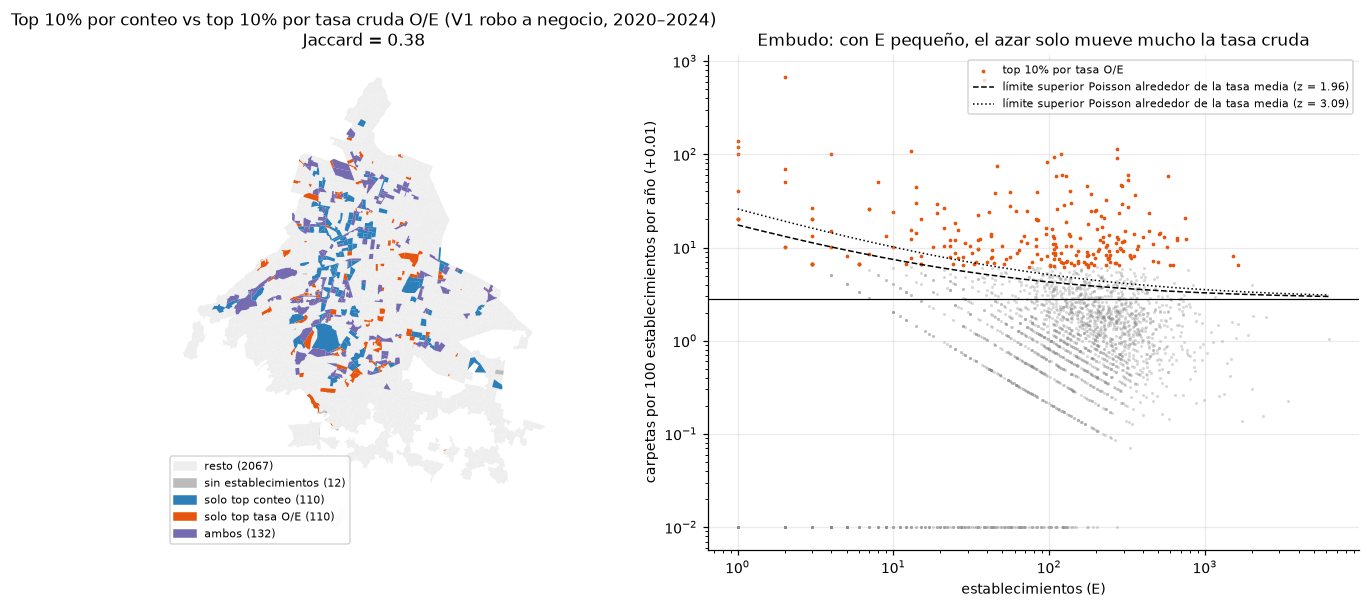

,Jaccard conteo vs O/E,E mediana top conteo,E mediana top O/E,% top O/E con E < 20
variable,,,,
V1,0.38,302.5,107.5,20.25
V2,0.22,352.5,83.0,23.55
V2b,0.20,354.0,84.0,22.73
V3,0.12,353.0,32.5,40.08


% de AGEB con E < 20: 8.8


In [10]:
geo = gpd.read_parquet(INTERIM / "ageb_geom.parquet").set_index("cvegeo")
k = "V1"
tasa = per[k] / per.E
tc, tr = top(per[k]), top(tasa)
cat = pd.Series("resto", index=geo.index)
cat[list(tc - tr)] = "solo top conteo"
cat[list(tr - tc)] = "solo top tasa O/E"
cat[list(tc & tr)] = "ambos"
cat[~geo.index.isin(per.index)] = "sin establecimientos"
colores = {"resto": "#eeeeee", "sin establecimientos": "#bbbbbb", "solo top conteo": "#2c7fb8",
           "solo top tasa O/E": "#e6550d", "ambos": "#756bb1"}

fig, axs = plt.subplots(1, 2, figsize=(12, 5.6), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axs[0]
for c_, col in colores.items():
    sub = geo[cat == c_]
    if len(sub):
        sub.plot(ax=ax, color=col, lw=0, label=f"{c_} ({len(sub)})")
ax.set_axis_off()
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colores[c_]) for c_ in colores],
          labels=[f"{c_} ({(cat == c_).sum()})" for c_ in colores], fontsize=7, loc="lower left")
ax.set_title(f"Top 10% por conteo vs top 10% por tasa cruda O/E ({NOMBRE[k]}, 2020–2024)\nJaccard = {jaccard(tc, tr):.2f}")

ax = axs[1]
ax.scatter(per.E, tasa * 100 / 5 + 0.01, s=4, alpha=0.3, color="gray", lw=0)
ax.scatter(per.E[list(tr)], tasa[list(tr)] * 100 / 5 + 0.01, s=6, color="#e6550d", lw=0, label="top 10% por tasa O/E")
lam = per[k].sum() / per.E.sum() / 5  # tasa media por establecimiento-año
x = np.geomspace(1, per.E.max(), 200)
ax.axhline(lam * 100, color="k", lw=0.8)
for z, ls in [(1.96, "--"), (3.09, ":")]:
    # O ~ Poisson(λ·E·5) ⇒ la tasa anual O/(5E) tiene DE = sqrt(λ / (5E))
    ax.plot(x, (lam + z * np.sqrt(lam / (x * 5))) * 100, ls, color="k", lw=1, label=f"límite superior Poisson alrededor de la tasa media (z = {z})")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("establecimientos (E)")
ax.set_ylabel("carpetas por 100 establecimientos por año (+0.01)")
ax.set_title("Embudo: con E pequeño, el azar solo mueve mucho la tasa cruda")
ax.legend(fontsize=7)
fig.tight_layout()
guarda(fig, "fig04_C_conteo_vs_tasa")
plt.show()

filas = []
for k_ in ["V1", "V2", "V2b", "V3"]:
    t_ = per[k_] / per.E
    a, b_ = top(per[k_]), top(t_)
    filas.append({"variable": k_, "Jaccard conteo vs O/E": jaccard(a, b_), "E mediana top conteo": per.E[list(a)].median(),
                  "E mediana top O/E": per.E[list(b_)].median(), "% top O/E con E < 20": np.mean(per.E[list(b_)] < 20) * 100})
display(pd.DataFrame(filas).set_index("variable").round(2))
print(f"% de AGEB con E < 20: {(per.E < 20).mean() * 100:.1f}")

In [11]:
# persistencia interanual de la tasa cruda O/E según el tamaño de la AGEB
w = p[p.E_fijo > 0].assign(r=lambda d: d.y_v1_negocio / d.E_fijo).pivot(index="cvegeo", columns="anio", values="r")
E = per.E
filas = []
for lo, hi in [(1, 20), (20, 100), (100, 300), (300, np.inf)]:
    ix = E[(E >= lo) & (E < hi)].index
    rhos = [stats.spearmanr(w.loc[ix, a], w.loc[ix, a + 1])[0] for a in range(2020, 2024)]
    filas.append({"E": f"[{lo}, {hi})", "AGEB": len(ix), "ρ medio O/E entre años consecutivos (2020–2024)": np.mean(rhos)})
display(pd.DataFrame(filas).set_index("E").round(2))

,AGEB,ρ medio O/E entre años consecutivos (2020–2024)
E,,
"[1, 20)",213,0.35
"[20, 100)",643,0.49
"[100, 300)",1132,0.63
"[300, inf)",431,0.75


**Lectura.**
- Priorizar por conteo y priorizar por tasa cruda dan listas muy distintas (Jaccard de 0.12 a 0.37 según la variable), pero **la tasa cruda no sirve como alternativa**. Su top 10% sobrerrepresenta las AGEB con menos de 20 establecimientos (20–40% del top frente a 9% de todas), justo donde la tasa es más inestable: su persistencia interanual cae a ρ ≈ 0.3–0.4, frente a ≈ 0.75 en las AGEB grandes.
- El embudo muestra dos cosas a la vez:
  - **Con E pequeño, el azar solo produce tasas enormes.** Con 1–5 establecimientos, una tasa de 10–25 carpetas por 100 establecimientos al año está dentro de la banda Poisson; con 100 o más, la misma tasa sería extraordinaria. Ordenar por tasa cruda premia esas AGEB por ruido.
  - **La heterogeneidad es real.** Buena parte del top por O/E queda muy por encima del límite incluso con E grande (cientos de establecimientos). Las diferencias entre AGEB no son solo azar Poisson (sobredispersión), así que una prueba Poisson pura marcaría cientos de AGEB como "anómalas".
- Juntas, motivan exactamente la **contracción Poisson-gamma** del diseño §6. La distribución gamma absorbe la heterogeneidad real, y la posterior reduce hacia 1 la tasa de las AGEB con poca información, mientras conserva el exceso de las que tienen información suficiente. También evita los dos sesgos de un residual crudo: el conteo O − E favorece a las AGEB grandes y O / E a las pequeñas. La hipótesis C se juzga con el residual contraído, no con estas tasas crudas.

## 6. Evidencia para S2–S4: el corte del DENUE, la validación temporal y 2019

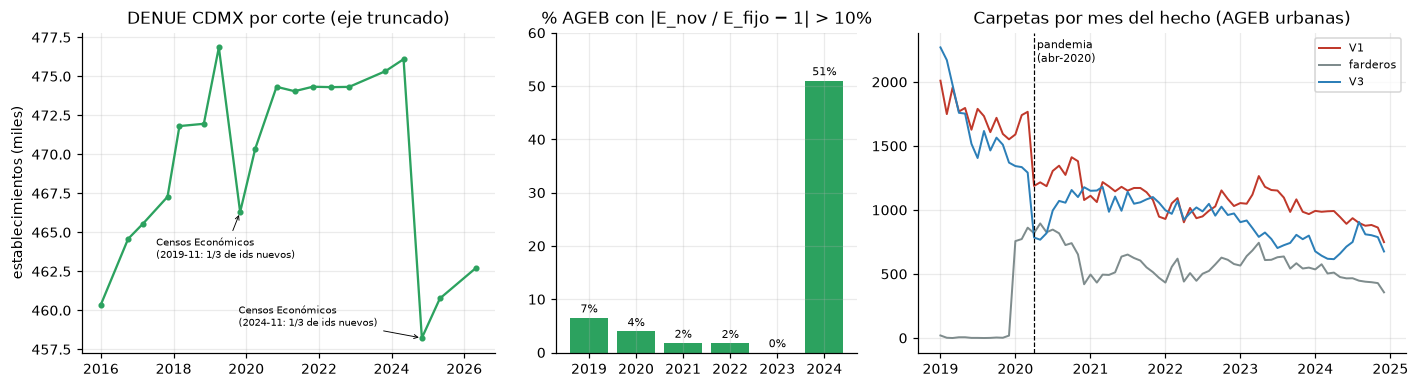

V1 promedio mensual 2019: 1742 | ene–mar 2020: 1699 | abr–dic 2020: 1265 | 2021–2024: 1038


In [12]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.1, 0.8, 1.3]})
# (a) serie DENUE (reutiliza la tabla del EDA de factibilidad)
serie = pd.read_csv(ROOT / "data/interim/_eda/q5_denue_serie.csv")
x = pd.to_datetime(serie.corte.str.replace("_", "-") + "-01")
ax = axs[0]
ax.plot(x, serie.n / 1000, "o-", color=COL["E"], ms=3)
for c_, off in [("2019_11", (-55, -30)), ("2024_11", (-120, 8))]:
    i = serie.index[serie.corte == c_][0]
    ax.annotate(f"Censos Económicos\n({c_.replace('_', '-')}: 1/3 de ids nuevos)", (x[i], serie.n[i] / 1000), fontsize=6.5,
                xytext=off, textcoords="offset points", arrowprops=dict(arrowstyle="->", lw=0.6))
ax.set_ylabel("establecimientos (miles)"); ax.set_title("DENUE CDMX por corte (eje truncado)")

# (b) % de AGEB cuyo E anual difiere >10% del E fijo (2023-11)
a = p[p.E_fijo > 0].assign(rel=lambda d: (d.E_nov / d.E_fijo - 1).abs())
dif = a.groupby("anio").rel.apply(lambda r: (r > 0.10).mean() * 100)
ax = axs[1]
ax.bar(dif.index, dif.values, color=COL["E"])
for xi, v in dif.items():
    ax.text(xi, v + 1, f"{v:.0f}%", ha="center", fontsize=7)
ax.set_title("% AGEB con |E_nov / E_fijo − 1| > 10%"); ax.set_ylim(0, 60)

# (c) serie mensual por año del hecho
dm = d[d.tipo_asig == "URBANA"].assign(m=lambda x: x.fecha_hecho.dt.to_period("M").dt.to_timestamp())
ms = pd.DataFrame({"V1": dm[dm.objetivo == "negocio"].groupby("m").size(),
                   "farderos": dm[dm.farderos == 1].groupby("m").size(),
                   "V3": dm[dm.objetivo == "via_publica"].groupby("m").size()}).fillna(0)
ax = axs[2]
for c_ in ms:
    ax.plot(ms.index, ms[c_], color=COL[c_], label=c_, lw=1.3)
ax.axvline(pd.Timestamp("2020-04-01"), color="k", ls="--", lw=0.8)
ax.text(pd.Timestamp("2020-04-15"), ms.values.max() * 0.95, "pandemia\n(abr-2020)", fontsize=7)
ax.set_title("Carpetas por mes del hecho (AGEB urbanas)"); ax.legend(fontsize=7)
fig.tight_layout()
guarda(fig, "fig05_S2_S4_denue_y_serie")
plt.show()

v1m = ms.V1
print(f"V1 promedio mensual 2019: {v1m['2019'].mean():.0f} | ene–mar 2020: {v1m['2020-01':'2020-03'].mean():.0f} | "
      f"abr–dic 2020: {v1m['2020-04':'2020-12'].mean():.0f} | 2021–2024: {v1m['2021':'2024'].mean():.0f}")

In [13]:
# β y ranking con E anual vs E fijo, y con o sin 2019
filas = []
for k, anios in [("V1", range(2019, 2025)), ("V1", range(2020, 2025)), ("V2", range(2020, 2025)), ("V2b", range(2020, 2025)),
                 ("V3", range(2019, 2025)), ("V3", range(2020, 2025))]:
    fila = {"variable": k, "periodo": f"{min(anios)}–2024"}
    for e in ["E_fijo", "E_nov"]:
        s = p[p.anio.isin(anios) & (p[e] > 0)]
        fe = pd.get_dummies(s.anio, drop_first=True).values
        b, se, _ = poisson(np.column_stack([np.log(s[e]), fe]), s[VARS[k]].values.astype(float))
        fila[f"β ({e})"] = b[1]
    filas.append(fila)
display(pd.DataFrame(filas).round(3))

# patrón espacial de cada año vs 2023 (Spearman de conteos por AGEB)
w = {k: p.pivot(index="cvegeo", columns="anio", values=VARS[k]) for k in ["V1", "V3"]}
display(pd.DataFrame({k: {a: stats.spearmanr(w[k][a], w[k][2023])[0] for a in range(2019, 2025) if a != 2023} for k in w}).T.round(3)
        .rename_axis("ρ con 2023"))
# composición: correlación de la proporción efectivo y grandes entre E anual y fijo en 2024 (cambio de marco)
c24 = p[(p.anio == 2024) & (p.E_fijo > 0) & (p.E_nov > 0)]
print("2024 — corr(E_nov, E_fijo) =", round(np.corrcoef(np.log(c24.E_nov), np.log(c24.E_fijo))[0, 1], 3),
      "| corr(% alto efectivo tradicional) =", round(c24[["ps_efectivo_barrio_nov", "ps_efectivo_barrio_fijo"]].corr().iloc[0, 1], 3),
      "| corr(% alto efectivo formal) =", round(c24[["ps_efectivo_formal_nov", "ps_efectivo_formal_fijo"]].corr().iloc[0, 1], 3),
      "| corr(p_grandes) =", round(c24[["p_grandes_nov", "p_grandes_fijo"]].corr().iloc[0, 1], 3))

,variable,periodo,β (E_fijo),β (E_nov)
0,V1,2019–2024,0.828,0.820
1,V1,2020–2024,0.808,0.805
2,V2,2020–2024,0.874,0.867
3,V2b,2020–2024,0.847,0.840
4,V3,2019–2024,0.686,0.685
5,V3,2020–2024,0.676,0.675


,2019,2020,2021,2022,2024
ρ con 2023,,,,,
V1,0.734,0.727,0.712,0.728,0.737
V3,0.682,0.668,0.692,0.688,0.665


2024 — corr(E_nov, E_fijo) = 0.986 | corr(% alto efectivo tradicional) = 0.896 | corr(% alto efectivo formal) = 0.761 | corr(p_grandes) = 0.909


**Lectura.**
- **S2 (corte del DENUE).** De 2019 a 2023 el E anual y el E fijo son prácticamente lo mismo: como mucho el 6.5% de las AGEB difiere más de 10% (2019) y menos del 2% desde 2021. β difiere en menos de 0.01 con cualquiera de los dos. La única diferencia real está en **2024**, donde la integración de los Censos Económicos 2024 reemplaza un tercio de los registros y la mitad de las AGEB cambia más de 10% sin que eso refleje dinámica económica. El E anual no aporta información y sí mete el artefacto censal de 2024.
- **S3 (validación temporal).** Por lo mismo, predecir 2024 con E = 2024-11 mezcla el desempeño del modelo con el cambio de marco del DENUE. Predecir con E = 2023-11 es lo que vería quien usara la lista para anticipar el año siguiente y coincide con la variante S2(b).
- **S4 (2019).** El nivel alto de 2019 **no** viene de la reclasificación: enero–marzo de 2020 tiene el mismo nivel mensual que 2019 y la caída empieza en abril de 2020, con la pandemia. El patrón espacial de 2019 es tan parecido al de 2023 como el de cualquier otro año (ρ ≈ 0.73). Para V1 y V3, 2019 es un año más con un nivel distinto, que el efecto fijo de año absorbe. Ojo: V3 ya venía cayendo durante 2019, antes de la pandemia (de ~2,250 a ~1,300 carpetas al mes), así que su tendencia es más fuerte que la de V1. Para V2/V2b no existe (no se puede separar a los farderos).

## 7. Concentración: delitos frente a establecimientos

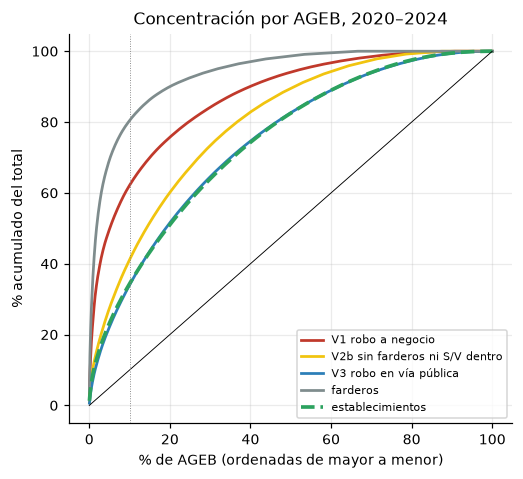

,V1,V2,V2b,V3,farderos,E
top 1%,25.2,13.5,11.1,7.8,38.0,9.4
top 5%,49.6,31.9,27.3,22.0,69.2,23.1
top 10%,62.1,45.5,41.0,33.9,80.4,34.3
top 25%,80.3,70.1,67.2,58.4,92.5,57.9


In [14]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for k, lab in [("V1", NOMBRE["V1"]), ("V2b", NOMBRE["V2b"]), ("V3", NOMBRE["V3"]), ("farderos", "farderos"), ("E", "establecimientos")]:
    s = np.sort(per[k].values)[::-1]
    cx = np.arange(1, len(s) + 1) / len(s) * 100
    cy = np.cumsum(s) / s.sum() * 100
    ax.plot(cx, cy, color=COL[k], lw=1.8 if k != "E" else 2.4, ls="-" if k != "E" else "--", label=lab)
ax.plot([0, 100], [0, 100], color="k", lw=0.6)
ax.axvline(10, color="gray", lw=0.6, ls=":")
ax.set_xlabel("% de AGEB (ordenadas de mayor a menor)"); ax.set_ylabel("% acumulado del total")
ax.set_title("Concentración por AGEB, 2020–2024")
ax.legend(fontsize=7, loc="lower right")
guarda(fig, "fig06_concentracion")
plt.show()
display(pd.DataFrame({k: {f"top {q}%": per[k].sort_values(ascending=False).iloc[: int(len(per) * q / 100)].sum() / per[k].sum() * 100
                          for q in (1, 5, 10, 25)} for k in ["V1", "V2", "V2b", "V3", "farderos", "E"]}).round(1))

**Lectura.** El robo a negocio está bastante más concentrado que los establecimientos: el top 10% de las AGEB acumula 62% de V1, frente a 34% de los establecimientos. La concentración viene sobre todo de los farderos (80% en el top 10%). Sin ellos (V2b, 41%) baja, pero sigue por encima de E. El robo en vía pública (34%) se reparte igual que los establecimientos. Una política que mire solo el conteo de V1 concentraría los recursos en unas pocas AGEB con autoservicios. Esto refuerza S1 y la hipótesis C.


## 8. Dependencia espacial: ¿el robo y su exceso se agrupan en el mapa?

Si las AGEB vecinas se parecen, los errores estándar que suponen independencia son optimistas y una validación cruzada aleatoria filtra información entre vecinos. Se mide con el **I de Moran**: vecindad *queen* (AGEB que comparten borde o vértice), pesos estandarizados por fila y 999 permutaciones, la misma especificación del chequeo de supuestos de `04_modelos.py`.

Además del robo y de los establecimientos, se mide el **exceso relativo** de cada AGEB, log((O + 0.5) / (Ê + 0.5)), donde Ê es el esperado de un Poisson descriptivo con log E. Es una versión cruda del residual de la hipótesis C: si se agrupa, la priorización formará zonas y no AGEB sueltas. El correlograma repite el I de Moran entre AGEB a 1, 2, …, 10 saltos de vecindad para ver hasta dónde llega la dependencia.

,I de Moran,p (999 permutaciones)
variable,,
"establecimientos, log E",0.310,0.001
"robo a negocio V2b, log(O + 1)",0.391,0.001
"robo en vía pública V3, log(O + 1)",0.428,0.001
exceso relativo V2b,0.305,0.001
exceso relativo V3,0.387,0.001


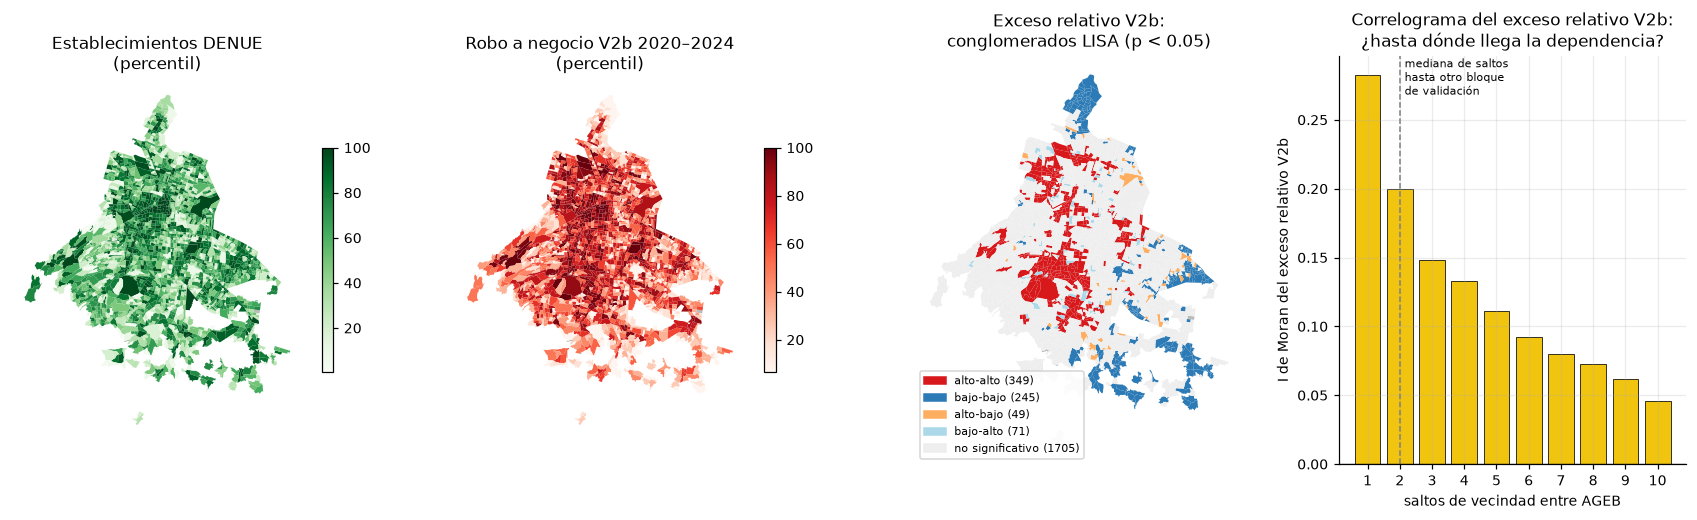

Correlograma: {1: 0.282, 2: 0.2, 3: 0.148, 4: 0.133, 5: 0.111, 6: 0.092, 7: 0.08, 8: 0.072, 9: 0.061, 10: 0.046}
Saltos hasta el bloque vecino: mediana 2, 61% a ≤ 2 saltos, 16% a ≥ 4
LISA: {'no significativo': 1705, 'alto-alto': 349, 'bajo-bajo': 245, 'bajo-alto': 71, 'alto-bajo': 49}
Alcaldías con más AGEB alto-alto: {'Coyoacán': 61, 'Cuauhtémoc': 45, 'Álvaro Obregón': 35, 'Tlalpan': 35, 'Azcapotzalco': 33, 'Benito Juárez': 31}
Alcaldías con más AGEB bajo-bajo: {'Iztapalapa': 92, 'Gustavo A. Madero': 64, 'Xochimilco': 32, 'Milpa Alta': 24, 'Tláhuac': 19, 'Tlalpan': 4}
Mediana de E: alto-alto 192.0 | bajo-bajo 128.0 | todas 142.0


In [15]:
# Dependencia espacial (2020–2024, AGEB con E > 0)
from esda.moran import Moran, Moran_Local
from libpysal.weights import Queen
from scipy.sparse.csgraph import shortest_path

from modelado import bloques

g8 = geo.loc[per.index]
wq = Queen.from_dataframe(g8, use_index=True, silence_warnings=True)  # una AGEB queda sin vecinos (isla)
wq.transform = "r"


def exceso(k):
    # log((O + 0.5) / (Ê + 0.5)) con Ê de un Poisson descriptivo O ~ log E
    b, _, _ = poisson(np.log(per.E.values), per[k].values.astype(float))
    mu = np.exp(b[0] + b[1] * np.log(per.E.values))
    return pd.Series(np.log((per[k].values + 0.5) / (mu + 0.5)), index=per.index)


ser = {"establecimientos, log E": np.log(per.E), "robo a negocio V2b, log(O + 1)": np.log1p(per.V2b),
       "robo en vía pública V3, log(O + 1)": np.log1p(per.V3),
       "exceso relativo V2b": exceso("V2b"), "exceso relativo V3": exceso("V3")}
filas = []
for nombre, x in ser.items():
    mi = Moran(x.values, wq, permutations=999)
    filas.append({"variable": nombre, "I de Moran": mi.I, "p (999 permutaciones)": mi.p_sim})
display(pd.DataFrame(filas).set_index("variable").round(3))

# correlograma: I de Moran entre pares de AGEB a exactamente k saltos de vecindad
A, ids = wq.full()
saltos = shortest_path(A, unweighted=True, directed=False)
z = ser["exceso relativo V2b"].loc[ids].values
z = z - z.mean()
correl = pd.Series({k_: len(z) / (saltos == k_).sum() * (z @ (saltos == k_).astype(float) @ z) / (z @ z) for k_ in range(1, 11)})

# ¿a cuántos saltos queda cada AGEB del bloque de validación vecino? (30 bloques de 04_modelos.py)
bl = bloques().bloque.reindex(ids).values
al_otro = np.where(bl[:, None] != bl[None, :], saltos, np.inf).min(axis=1)
al_otro = al_otro[np.isfinite(al_otro)]

# LISA del exceso V2b (p < 0.05 sin corrección por comparaciones múltiples: descriptivo)
lisa = Moran_Local(ser["exceso relativo V2b"].values, wq, permutations=999, seed=1)
etiq = np.array(["", "alto-alto", "bajo-alto", "bajo-bajo", "alto-bajo"])[lisa.q]
clase = pd.Series(np.where(lisa.p_sim < 0.05, etiq, "no significativo"), index=per.index)

fig, axs = plt.subplots(1, 4, figsize=(15.5, 4.8), gridspec_kw={"width_ratios": [1, 1, 1, 0.95]})
fondo = geo.drop(per.index)
for ax, v, tit, cmap in [(axs[0], per.E, "Establecimientos DENUE\n(percentil)", "Greens"),
                         (axs[1], per.V2b, "Robo a negocio V2b 2020–2024\n(percentil)", "Reds")]:
    fondo.plot(ax=ax, color="#bbbbbb", lw=0)
    g8.assign(v=v.rank(pct=True) * 100).plot(ax=ax, column="v", cmap=cmap, lw=0, legend=True,
                                             legend_kwds={"shrink": 0.55})
    ax.set_title(tit); ax.set_axis_off()
col_lisa = {"alto-alto": "#d7191c", "bajo-bajo": "#2c7bb6", "alto-bajo": "#fdae61", "bajo-alto": "#abd9e9",
            "no significativo": "#eeeeee"}
ax = axs[2]
fondo.plot(ax=ax, color="#bbbbbb", lw=0)
for c_, col in col_lisa.items():
    sub = g8[clase == c_]
    if len(sub):
        sub.plot(ax=ax, color=col, lw=0)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in col_lisa.values()],
          labels=[f"{c_} ({(clase == c_).sum()})" for c_ in col_lisa], fontsize=7, loc="lower left")
ax.set_title("Exceso relativo V2b:\nconglomerados LISA (p < 0.05)"); ax.set_axis_off()
ax = axs[3]
ax.bar(correl.index, correl.values, color=COL["V2b"], edgecolor="k", lw=0.5)
ax.axhline(0, color="k", lw=0.8)
ax.axvline(np.median(al_otro), color="gray", ls="--", lw=1)
ax.text(np.median(al_otro) + 0.15, correl.max() * 0.95, "mediana de saltos\nhasta otro bloque\nde validación", fontsize=7)
ax.set_xticks(correl.index)
ax.set_xlabel("saltos de vecindad entre AGEB"); ax.set_ylabel("I de Moran del exceso relativo V2b")
ax.set_title("Correlograma del exceso relativo V2b:\n¿hasta dónde llega la dependencia?")
fig.tight_layout()
guarda(fig, "fig08_dependencia_espacial")
plt.show()

print("Correlograma:", correl.round(3).to_dict())
print(f"Saltos hasta el bloque vecino: mediana {np.median(al_otro):.0f}, "
      f"{(al_otro <= 2).mean() * 100:.0f}% a ≤ 2 saltos, {(al_otro >= 4).mean() * 100:.0f}% a ≥ 4")
print("LISA:", clase.value_counts().to_dict())
hh = clase[clase == "alto-alto"].index
print("Alcaldías con más AGEB alto-alto:", per.loc[hh, "alcaldia"].value_counts().head(6).to_dict())
ll = clase[clase == "bajo-bajo"].index
print("Alcaldías con más AGEB bajo-bajo:", per.loc[ll, "alcaldia"].value_counts().head(6).to_dict())
print("Mediana de E: alto-alto", per.E[hh].median(), "| bajo-bajo", per.E[ll].median(), "| todas", per.E.median())


**Lectura.**
- **Todo se agrupa.** Los establecimientos (I = 0.31), el robo a negocio (0.39) y el robo en vía pública (0.43) tienen autocorrelación positiva (p = 0.001). Que el robo siga al comercio es lo esperado: los dos primeros mapas se parecen.
- **Lo no obvio: el exceso también se agrupa.** Aun después de descontar el número de negocios, las AGEB vecinas se parecen (I = 0.31 en V2b, 0.39 en V3). El exceso no es ruido de cada AGEB: forma zonas. Hay 349 AGEB en conglomerados alto-alto (sobre todo en Coyoacán, Cuauhtémoc, Álvaro Obregón, Tlalpan, Azcapotzalco y Benito Juárez) y 245 en bajo-bajo (Iztapalapa, Gustavo A. Madero, Xochimilco, Milpa Alta y Tláhuac). Los p del LISA no están corregidos por comparaciones múltiples, así que el mapa es descriptivo.
- **Este mapa no es la lista de prioridades.** El exceso crudo solo descuenta el número de negocios. Los conglomerados bajo-bajo de la periferia coinciden con las zonas de comercio tradicional, donde se denuncia menos (§4 y §9): no hay que leerlos como zonas más seguras. El modelo descuenta además giro, tamaño y población, y por eso su lista (hipótesis C) cambia respecto a este mapa.
- **La dependencia tiene dos escalas.** El correlograma cae de 0.28 entre vecinos inmediatos a 0.15 a tres saltos, pero sigue siendo positivo a diez saltos (0.05). Hay conglomerados locales y, además, un gradiente amplio que cruza la ciudad.
- **Implicaciones para el modelado:**
  - Los errores estándar que suponen independencia serían optimistas. El IC de β (hipótesis A) se calcula por *bootstrap* de bloques espaciales.
  - Una validación cruzada aleatoria pondría vecinos casi idénticos en entrenamiento y prueba. Se valida por bloques espaciales (30 bloques de ~80 AGEB).
  - Los bloques reducen esa fuga, pero no la eliminan: la AGEB mediana está a 2 saltos de otro bloque (61% a 2 saltos o menos), donde la dependencia sigue siendo de 0.20. Por eso el error medido fuera de muestra se lee como algo optimista, y así se declara.
  - Como el exceso forma zonas, la priorización se puede leer por colonia o por corredor, no solo por AGEB suelta. La app ofrece esos niveles.
  - El chequeo de supuestos de `04_modelos.py` confirma la lectura: con los controles del modelo, el I de Moran de los residuales baja a 0.12, pero sigue siendo significativo.


## 9. Contexto ENVE: la propensión a denunciar crece con el tamaño de la empresa

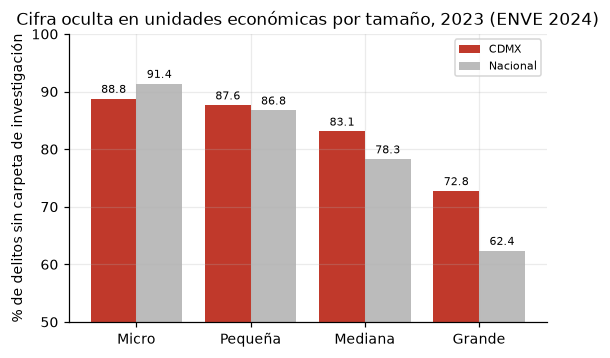

,CDMX,Nacional
nivel,,
Micro,88.8,91.4
Pequeña,87.6,86.8
Mediana,83.1,78.3
Grande,72.8,62.4


In [16]:
f = RAW / "encuestas/enve2024/conjunto_de_datos/enve2024_iii_denuncia_delito/t3_8.csv"
t = pd.read_csv(f, encoding="utf-8")
t.columns = ["nivel", "cifra"]
t = t.dropna()
fila_ent = t.index[~t.nivel.isin(["Micro", "Pequeña", "Mediana", "Grande"])]
t["entidad"] = pd.Series(t.nivel.where(t.index.isin(fila_ent))).ffill()
t["cifra"] = pd.to_numeric(t.cifra)
tam = ["Micro", "Pequeña", "Mediana", "Grande"]
enve = t[t.nivel.isin(tam)].pivot(index="nivel", columns="entidad", values="cifra").loc[tam, ["Ciudad de México", "Estados Unidos Mexicanos"]]
enve.columns = ["CDMX", "Nacional"]

fig, ax = plt.subplots(figsize=(5.6, 3.4))
xx = np.arange(len(tam))
ax.bar(xx - 0.2, enve.CDMX, 0.4, color="#c0392b", label="CDMX")
ax.bar(xx + 0.2, enve.Nacional, 0.4, color="#bbbbbb", label="Nacional")
for i, (a_, b_) in enumerate(zip(enve.CDMX, enve.Nacional)):
    ax.text(i - 0.2, a_ + 1, f"{a_:.1f}", ha="center", fontsize=7)
    ax.text(i + 0.2, b_ + 1, f"{b_:.1f}", ha="center", fontsize=7)
ax.set_xticks(xx, tam); ax.set_ylim(50, 100)
ax.set_ylabel("% de delitos sin carpeta de investigación")
ax.set_title("Cifra oculta en unidades económicas por tamaño, 2023 (ENVE 2024)")
ax.legend(fontsize=7)
guarda(fig, "fig07_enve_cifra_oculta")
plt.show()
display(enve.round(1))

**Lectura.** En la CDMX, la empresa micro no denuncia el 88.8% de los delitos que sufre, y la grande el 72.8%. Visto al revés, la grande lleva a carpeta 2.4 veces más delitos que la micro (27.2% vs 11.2%). Esto no se puede corregir por AGEB (la ENVE solo llega a nivel estatal), pero explica dos hallazgos de este EDA: que las AGEB con autoservicios grandes dominen el robo a negocio (§3) y que las AGEB de tienditas parezcan "seguras" (§4). En los modelos se mitiga con `p_grandes` y con S1, y se declara como limitación en las conclusiones.


## 10. Qué informa este EDA al modelado

| Hallazgo | Implicación |
|---|---|
| β descriptivo < 1 en las tres variantes (0.69–0.87) | La hipótesis A es plausible; el modelado debe confirmarla con NB, controles e IC por bootstrap espacial |
| Los farderos y "S/V dentro" curvan la relación y dominan el top (autoservicios grandes) | S1: la variable principal debe excluirlos (V2b recomendada); V1 como sensibilidad |
| La lista tentativa de "efectivo" mezcla comercio tradicional (RR < 1) y formal o de cadena (RR > 1) | Lista SCIAN: dos grupos definidos por tipo de negocio, no uno |
| E anual = E fijo hasta 2023; en 2024 el cambio de marco es artefacto | S2(b) E fijo y S3(a) predecir 2024 con E 2023-11 |
| 2019 alto por la pandemia (no por la reclasificación); mismo patrón espacial | S4: incluir 2019 en V1/V3 con efecto fijo de año; V2/V2b empiezan en 2020 |
| La tasa cruda O/E es ruido en E pequeño; el conteo favorece a las AGEB grandes | Contracción Poisson-gamma obligatoria para C |
| Sobredispersión fuerte (var/media ≫ 1) | NB2 sobre Poisson (prueba formal al modelar) |
| Autocorrelación espacial del robo y de su exceso: conglomerados locales más un gradiente amplio | IC de β por bootstrap de bloques espaciales y validación por bloques, no aleatoria; la priorización se lee por zonas (colonia, alcaldía), no solo por AGEB suelta |
| Gradiente de denuncia por tamaño (ENVE) | Control `p_grandes`; limitación declarada |

El detalle de cada decisión, con opciones e implicaciones, está en `analisis/pipeline/outputs/eda/decisiones.md`.

**Cómo se resolvieron.** Cada recomendación se sometió a experimentos con reglas de decisión declaradas antes de correrlos (`analisis/lab/README.md`). Los resultados (`analisis/lab/resultados/decisiones_lab.md`) confirmaron las cinco: V2b como variable principal, lista de efectivo en dos grupos, E fijo 2023-11, validación temporal con E 2023-11 y 2019 incluido en V1/V3. Quedan registradas en `docs/5.Diseno-Experimental.md` §3.1.
